In [1]:
! pip install langchain langchain-openai langchain-community langgraph python-dotenv faiss-cpu pypdf

Defaulting to user installation because normal site-packages is not writeable
  Using cached tiktoken-0.14.0-cp313-cp313-win_amd64.whl.metadata (6.8 kB)
  Using cached jiter-0.19.0-cp313-cp313-win_amd64.whl.metadata (5.3 kB)
   ---------------------------------------- 0.0/591.1 kB ? eta -:--:--
   ---------------------------------------- 591.1/591.1 kB 3.0 MB/s  0:00:00
   ---------------------------------------- 0.0/16.6 MB ? eta -:--:--
   - -------------------------------------- 0.8/16.6 MB 4.5 MB/s eta 0:00:04
   --- ------------------------------------ 1.3/16.6 MB 3.5 MB/s eta 0:00:05
   ----- ---------------------------------- 2.4/16.6 MB 3.9 MB/s eta 0:00:04
   ------- -------------------------------- 3.1/16.6 MB 4.1 MB/s eta 0:00:04
   ------- -------------------------------- 3.1/16.6 MB 4.1 MB/s eta 0:00:04
   -------- ------------------------------- 3.7/16.6 MB 2.9 MB/s eta 0:00:05
   ---------- ----------------------------- 4.2/16.6 MB 3.1 MB/s eta 0:00:04
   ----------- ---


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip


In [2]:
from langchain_google_genai import ChatGoogleGenerativeAI,GoogleGenerativeAIEmbeddings
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition

C:\Users\PRIYAM PATRA\AppData\Local\Temp\ipykernel_23572\2492584256.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [3]:
load_dotenv()

True

In [4]:
llm = ChatGoogleGenerativeAI(model='gemini-3.8-flash')

In [6]:
loader = PyPDFLoader("PS_10.pdf")
docs = loader.load()

In [7]:
len(docs)

12

In [8]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(docs)

In [9]:
len(chunks)

20

In [10]:
embeddings = GoogleGenerativeAIEmbeddings(model='gemini-embedding-001')
vector_store = FAISS.from_documents(chunks, embeddings)

In [11]:
vector_store

In [12]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [13]:
@tool
def rag_tool(query):

    """
    Retrieve relevant information from the pdf document.
    Use this tool when the user asks factual / conceptual questions
    that might be answered from the stored documents.
    """
    result = retriever.invoke(query)

    context = [doc.page_content for doc in result]
    metadata = [doc.metadata for doc in result]

    return {
        'query': query,
        'context': context,
        'metadata': metadata
    }

In [15]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

In [14]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [16]:
def chat_node(state: ChatState):

    messages = state['messages']

    response = llm_with_tools.invoke(messages)

    return {'messages': [response]}

In [17]:
tool_node = ToolNode(tools)

In [18]:
graph = StateGraph(ChatState)

graph.add_node('chat_node', chat_node)
graph.add_node('tools', tool_node)

graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node', tools_condition)
graph.add_edge('tools', 'chat_node')

chatbot = graph.compile()

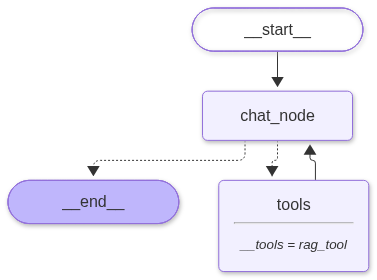

In [19]:
chatbot

In [22]:
result = chatbot.invoke(
    {
        "messages": [
            HumanMessage(
                content=(
                    "Using the pdf notes, explain how to find the ideal value of K in KNN"
                )
            )
        ]
    }
)

GoogleAPIError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [21]:
print(result['messages'][-1].content)

NameError: name 'result' is not defined